# Yu et al. 2024: a 2D ResNet34 with hard and soft voting

## 1. Paper summary and reference

S. Yu, X. Liang, S. Zhao, Y. Xie, Q. Sun, *Three-dimensional automated breast ultrasound (ABUS) tumor classification using a 2D-input network: soft voting or hard voting?*, Applied Sciences 14(24):11611 (2024), [doi:10.3390/app142411611](https://doi.org/10.3390/app142411611).

A 2D network classifies each tumor slice, and the slices are combined per volume. Hard voting (Eq. 3) takes the majority of slices. Soft voting (Eq. 1) weights each slice's probability by its tumor voxels. We implement Sections 2.2, 2.4 and 2.5 for ResNet34, the paper's best network.

In [1]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from abus_classification.papers.yu2024 import YuResNet
from abus_classification.papers.yu2024.pipeline import votes
from abus_classification.protocol import auc_ci

RESULTS = Path("../results/yu2024")
table = pd.read_csv(RESULTS / "yu2024_results.csv", index_col=0)
slices = np.load(RESULTS / "yu2024_test_slices.npz")
case, voxels, y = slices["case"], slices["voxels"], slices["y"]
MODES = ["resnet34", "resnet34_crop", "resnet34_scratch"]
COLORS = dict(resnet34="#2a78d6", resnet34_crop="#4a3aa7", resnet34_scratch="#898781")

## 2. Implementation details

| Item | Paper | Ours | Status |
|---|---|---|---|
| Samples | Slices with tumor, 2028 on Train (Section 2.4) | Axis 2 slices with tumor, **3170** on Train | **Differs**, unexplained (Section 7) |
| Network | ResNet34 (also MedViT, HiFuse, MedMamba, 3D networks) | ResNet34 only | **Deviation**: it is the paper's best |
| Epochs | 100 | 100, last epoch used | Follows |
| Soft voting | Eq. 1, voxel-weighted mean | Same, `votes` | Follows |
| Hard voting | Eq. 3, majority of slices | Share of malignant slices; a tie counts as malignant | Tie is **assumed** |
| Weights | Tumor voxels per slice | From ground-truth masks | Follows; a real system needs a segmentation first |
| Evaluation | Five-fold CV on Train (100) | Train + Validation to Test (70), 3 seeds; plus five-fold CV on Train, one seed | **Deviation**, with the paper's protocol as well |
| Input | Whole slices in Fig. 2; "smaller slices" in the discussion | Whole slices; `resnet34_crop` uses the slice's lesion box | **Assumed**, both run |
| Pretraining | Not given | ImageNet; `resnet34_scratch` without | **Assumed**, both run |
| Size | Not given | 224 x 224, ignoring aspect ratio | **Assumed** |
| Optimizer, loss | Not given | Adam, lr 1e-4, batch 32, cross-entropy | **Assumed** |
| Augmentation | Not given | None | **Assumed** |

## 3. Verification of the implementation

Unit tests are in `test/papers_tests/test_yu2024.py`: slice extraction and voxel counts, hand-computed votes, parameter count and an overfit run with a tiny stand-in network.

In [2]:
net = YuResNet(pretrained=False).eval()
print("output", tuple(net(torch.zeros(2, 1, 224, 224)).shape), "parameters", f"{sum(p.numel() for p in net.parameters()):,}")
_, hard, soft = votes(np.array([0.9, 0.2, 0.2]), np.array([800, 100, 100]), np.zeros(3, int))
print("one large malignant slice, two small benign: hard", round(hard[0], 3), "soft", round(soft[0], 3), "(by hand: 1/3 and 0.76)")

output (2, 2) parameters 21,285,698
one large malignant slice, two small benign: hard 0.333 soft 0.76 (by hand: 1/3 and 0.76)


**Stored predictions reproduce the Kaggle table.** The slice map comes from the local Test masks, and the probabilities from the kernel.

In [3]:
rows = []
for mode in MODES:
    for seed in range(3):
        p = np.load(RESULTS / f"yu2024_{mode}_seed{seed}.npz")["prob"]
        _, hard, soft = votes(p, voxels, case)
        rows.append(dict(run=f"{mode} seed {seed}", soft=roc_auc_score(y, soft), soft_table=table.loc[f"{mode} soft seed {seed}", "AUC"],
                         hard=roc_auc_score(y, hard), hard_table=table.loc[f"{mode} hard seed {seed}", "AUC"]))
check = pd.DataFrame(rows).set_index("run").round(4)
assert np.allclose(check.soft, check.soft_table, atol=2e-4) and np.allclose(check.hard, check.hard_table, atol=2e-4)
check

,soft,soft_table,hard,hard_table
run,,,,
resnet34 seed 0,0.7250,0.7250,0.7062,0.7062
resnet34 seed 1,0.7900,0.7900,0.7712,0.7712
resnet34 seed 2,0.7208,0.7208,0.7067,0.7067
resnet34_crop seed 0,0.8175,0.8175,0.7971,0.7971
resnet34_crop seed 1,0.8125,0.8125,0.7967,0.7967
resnet34_crop seed 2,0.8075,0.8075,0.7704,0.7704
resnet34_scratch seed 0,0.6950,0.6950,0.6583,0.6583
resnet34_scratch seed 1,0.6017,0.6017,0.5804,0.5804
resnet34_scratch seed 2,0.6983,0.6983,0.7012,0.7012


**The paper's own numbers do not fit together.** With 58 malignant and 42 benign cases, accuracy follows from sensitivity and specificity. Its voting rows also report AUC equal to accuracy.

In [4]:
paper = pd.DataFrame({"ResNet34": (0.865, 0.942, 0.757, 0.936), "ResNet34 + HV": (0.907, 0.990, 0.864, 0.907), "ResNet34 + SV": (0.986, 0.990, 0.963, 0.986),
                      "MedMamba + SV": (0.954, 0.975, 0.943, 0.954)}, index=["ACC", "SEN", "SPE", "AUC"]).T
paper["ACC from SEN, SPE"] = ((58 * paper.SEN + 42 * paper.SPE) / 100).round(3)
paper

,ACC,SEN,SPE,AUC,"ACC from SEN, SPE"
ResNet34,0.865,0.942,0.757,0.936,0.864
ResNet34 + HV,0.907,0.990,0.864,0.907,0.937
ResNet34 + SV,0.986,0.990,0.963,0.986,0.979
MedMamba + SV,0.954,0.975,0.943,0.954,0.962


Fold averages can shift this a little, since folds differ in class balance, but the 0.03 gap for hard voting is large. No code is published to settle it.

**Fast training accuracy.** Training accuracy passes 99% at epoch 2 on whole slices and about epoch 10 on crops. Test AUC is well above chance, so the labels are intact. The likely cause is memorising volumes: a volume's slices look alike and share a label. That is a hypothesis, and a label-shuffling run has not tested it.

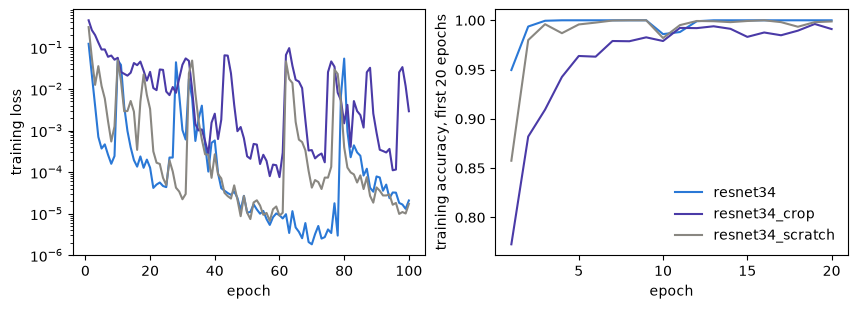

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for mode in MODES:
    h = pd.read_csv(RESULTS / f"yu2024_{mode}_seed0_history.csv")
    ax[0].plot(h.epoch, h.loss, color=COLORS[mode], label=mode); ax[1].plot(h.epoch.head(20), h.acc.head(20), color=COLORS[mode], label=mode)
ax[0].set(xlabel="epoch", ylabel="training loss", yscale="log"); ax[1].set(xlabel="epoch", ylabel="training accuracy, first 20 epochs"); ax[1].legend(frameon=False)
plt.show()

## 4. Images

**Method**, redrawn from the paper's Fig. 2: tumor slices, then ResNet34 per slice, then voting weighted by tumor voxels. **Our outputs**: the training curves above, and ROC curves and slices per volume below.

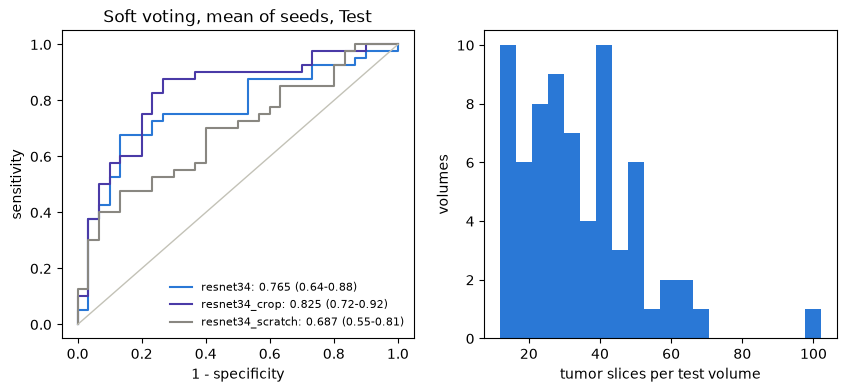

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for mode in MODES:
    mean = np.mean([votes(np.load(RESULTS / f"yu2024_{mode}_seed{s}.npz")["prob"], voxels, case)[2] for s in range(3)], 0)
    fpr, tpr, _ = roc_curve(y, mean)
    low, high = auc_ci(y, mean)
    ax[0].plot(fpr, tpr, color=COLORS[mode], label=f"{mode}: {roc_auc_score(y, mean):.3f} ({low:.2f}-{high:.2f})")
ax[0].plot([0, 1], [0, 1], color="#c3c2b7", lw=1); ax[0].set(xlabel="1 - specificity", ylabel="sensitivity", title="Soft voting, mean of seeds, Test"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.bincount(case), bins=20, color="#2a78d6"); ax[1].set(xlabel="tumor slices per test volume", ylabel="volumes")
plt.show()

### Sample inputs and what the model did

Lesion crops with soft voting, the mean of 3 seeds with the paper's defaults, on four test volumes: the most confident correct malignant and benign, and the worst wrong malignant and benign. Each row shows the largest tumor slice with the ground-truth contour, the crop the network receives, and the network's output for every tumor slice with the voxels that weight it in the vote. The cell reads the four volumes through the dataset library and runs no network; the probabilities are the stored Kaggle predictions.

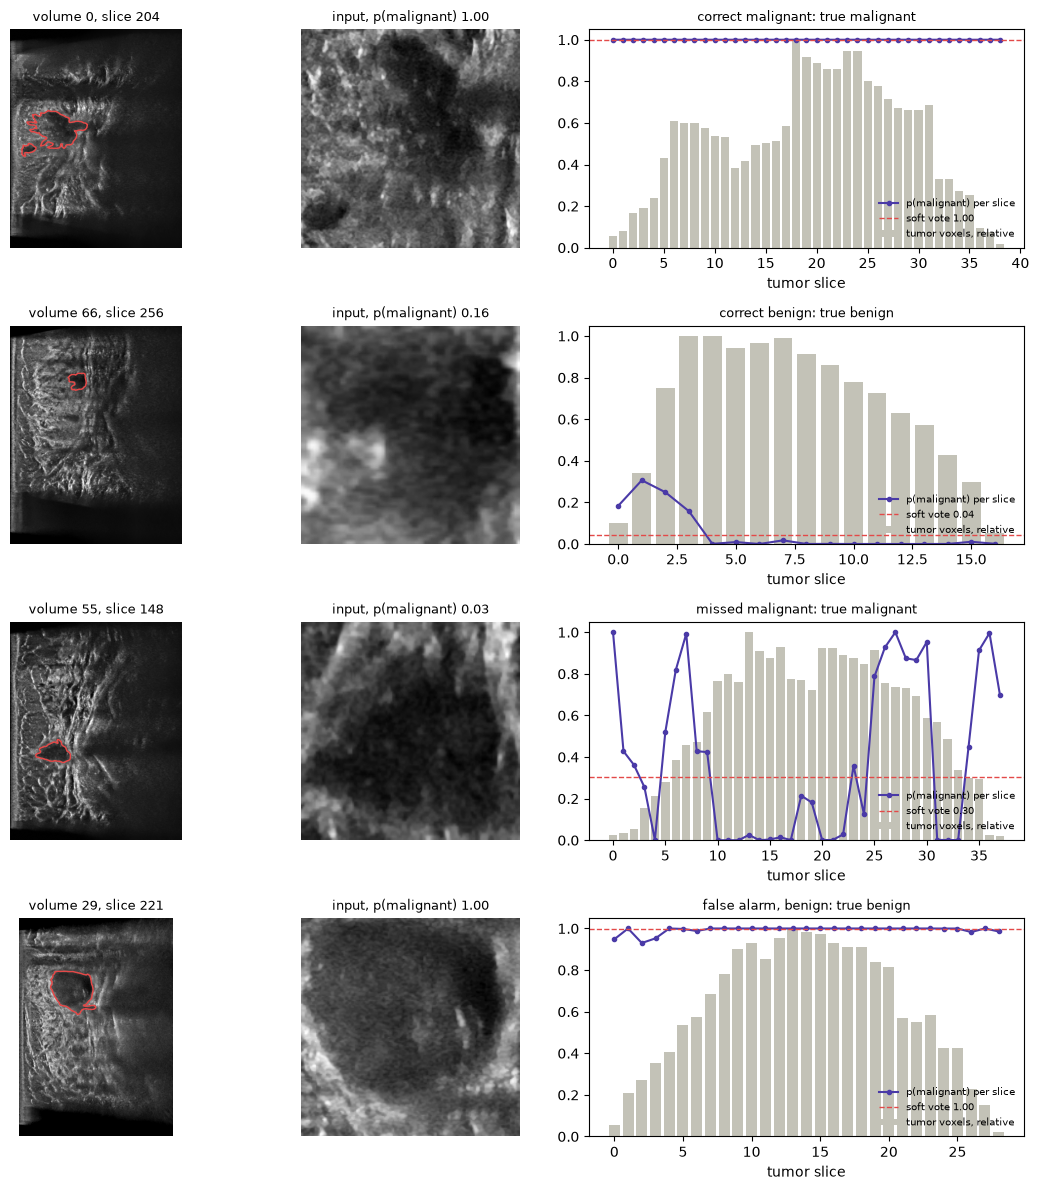

{'correct malignant': (0, 1.0), 'correct benign': (66, 0.044), 'missed malignant': (55, 0.304), 'false alarm, benign': (29, 0.997)}


In [7]:
from tdsc_abus2023_pytorch import TDSC, DataSplits
from abus_classification.data.lesion_cache import TDSC_PATH
from abus_classification.papers.yu2024.pipeline import tumor_slices

probs = np.mean([np.load(RESULTS / f"yu2024_resnet34_crop_seed{s}.npz")["prob"] for s in range(3)], 0)
soft = votes(probs, voxels, case)[2]
order = np.argsort(soft)
malignant, benign = order[y[order] == 1], order[y[order] == 0]
picks = [("correct malignant", malignant[-1]), ("correct benign", benign[0]), ("missed malignant", malignant[0]), ("false alarm, benign", benign[-1])]
test = TDSC(path=TDSC_PATH, split=DataSplits.TEST, download=False)

fig, ax = plt.subplots(len(picks), 3, figsize=(11, 3 * len(picks)), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
for row, (title, c) in zip(ax, picks):
    vol, mask, _, _ = test[c]
    vol, mask = np.asarray(vol), np.asarray(mask) > 0
    whole, crop, vox = tumor_slices(vol, mask)
    at = case == c
    assert np.array_equal(vox, voxels[at])                 # the stored slice map matches this volume
    big = vox.argmax()
    z = np.flatnonzero(mask.any((0, 1)))[big]
    row[0].imshow(vol[:, :, z], cmap="gray"); row[0].contour(mask[:, :, z], levels=[0.5], colors="#e34948", linewidths=1)
    row[0].set_title(f"volume {c}, slice {z}", fontsize=9); row[0].axis("off")
    row[1].imshow(crop[big], cmap="gray"); row[1].set_title(f"input, p(malignant) {probs[at][big]:.2f}", fontsize=9); row[1].axis("off")
    x = np.arange(len(vox))
    row[2].bar(x, vox / vox.max(), color="#c3c2b7", label="tumor voxels, relative")
    row[2].plot(x, probs[at], "o-", ms=3, color=COLORS["resnet34_crop"], label="p(malignant) per slice")
    row[2].axhline(soft[c], color="#e34948", ls="--", lw=1, label=f"soft vote {soft[c]:.2f}")
    row[2].set(ylim=(0, 1.05), xlabel="tumor slice"); row[2].set_title(f"{title}: true {'malignant' if y[c] else 'benign'}", fontsize=9)
    row[2].legend(frameon=False, fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()
print({t: (int(c), round(float(soft[c]), 3)) for t, c in picks})

## 5. Tables

The paper's numbers are five-fold CV on Train. Compare them with our CV rows, which use the same split sizes. The paper reports no seed variance. Its AUC for voting looks computed from labels, so `Balanced`, (sensitivity + specificity) / 2, is the closest match to those rows, and `AUC` here always comes from continuous scores.

In [8]:
cols = ["AUC", "Balanced", "Acc", "Sens", "Spec", "Score"]
held = []
for mode in MODES:
    for kind in ("slices", "hard", "soft"):
        t = table.loc[[f"{mode} {kind} seed {s}" for s in range(3)], cols]
        held.append(pd.Series({**t.mean().round(3).to_dict(), "AUC seed sd": round(t.AUC.std(), 3)}, name=f"{mode} {kind}"))
display(pd.DataFrame(held))
cv = table.loc[[i for i in table.index if i.endswith(" cv")], cols].round(3)
pp = pd.DataFrame({"paper ResNet34": (0.936, 0.865, 0.942, 0.757), "paper + HV": (0.907, 0.907, 0.990, 0.864), "paper + SV": (0.986, 0.986, 0.990, 0.963)}, index=["AUC", "Acc", "Sens", "Spec"]).T
display(cv); display(pp)
diff = pd.Series({"slices": cv.loc["resnet34_crop slices cv", "AUC"] - 0.936, "hard": cv.loc["resnet34_crop hard cv", "AUC"] - 0.907, "soft": cv.loc["resnet34_crop soft cv", "AUC"] - 0.986}, name="our best CV AUC minus paper").round(3)
diff

,AUC,Balanced,Acc,Sens,Spec,Score,AUC seed sd
resnet34 slices,0.749,0.672,0.698,0.754,0.590,0.723,0.024
resnet34 hard,0.728,0.654,0.671,0.775,0.533,0.700,0.037
resnet34 soft,0.745,0.679,0.695,0.792,0.567,0.720,0.039
resnet34_crop slices,0.719,0.616,0.685,0.832,0.401,0.702,0.010
resnet34_crop hard,0.788,0.647,0.686,0.917,0.378,0.737,0.015
resnet34_crop soft,0.812,0.662,0.700,0.925,0.400,0.756,0.005
resnet34_scratch slices,0.689,0.628,0.668,0.754,0.502,0.679,0.029
resnet34_scratch hard,0.647,0.614,0.638,0.783,0.444,0.642,0.061
resnet34_scratch soft,0.665,0.597,0.624,0.783,0.411,0.644,0.055


,AUC,Balanced,Acc,Sens,Spec,Score
resnet34 slices cv,0.695,0.648,0.672,0.716,0.579,0.684
resnet34 hard cv,0.705,0.692,0.700,0.742,0.642,0.703
resnet34 soft cv,0.709,0.684,0.690,0.726,0.642,0.699
resnet34_crop slices cv,0.741,0.668,0.713,0.801,0.536,0.727
resnet34_crop hard cv,0.828,0.728,0.750,0.880,0.575,0.789
resnet34_crop soft cv,0.846,0.760,0.780,0.897,0.622,0.813


,AUC,Acc,Sens,Spec
paper ResNet34,0.936,0.865,0.942,0.757
paper + HV,0.907,0.907,0.990,0.864
paper + SV,0.986,0.986,0.990,0.963


slices   -0.195
hard     -0.079
soft     -0.140
Name: our best CV AUC minus paper, dtype: float64

### Paper defaults against early stopping

**Why a second run.** The paper's fixed 100 epochs reach about 100% training accuracy, by epoch 2 on whole slices (Section 3), so the last epoch is a memorised model. The paper gives no stopping rule. The second run (`yu2024_es_*`, our addition, not the paper's method) stops after 10 epochs without improvement, picks the epoch by soft-voting AUC on the official Validation split, and halves the learning rate on a plateau.

**The two runs differ in training data.** Early stopping needs Validation, so it fits Train only (100 volumes), against Train + Validation (130) for the defaults. A difference between them is not due to stopping alone.

In [9]:
es = pd.read_csv(RESULTS / "yu2024_es_results.csv", index_col=0)
for mode in MODES:                                  # stored predictions reproduce the early-stopping table too
    for s in range(3):
        soft = votes(np.load(RESULTS / f"yu2024_es_{mode}_seed{s}.npz")["prob"], voxels, case)[2]
        assert abs(roc_auc_score(y, soft) - es.loc[f"{mode} soft seed {s}", "AUC"]) < 2e-4

def ensemble(prefix, mode):
    return np.mean([votes(np.load(RESULTS / f"{prefix}_{mode}_seed{s}.npz")["prob"], voxels, case)[2] for s in range(3)], 0)

def paired(a, b, n=2000):
    rng, d = np.random.default_rng(0), []
    while len(d) < n:
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(y):
            d.append(roc_auc_score(y[i], b[i]) - roc_auc_score(y[i], a[i]))
    return np.percentile(d, [2.5, 97.5])

rows = []
for mode in MODES:
    seeds = lambda t: t.loc[[f"{mode} soft seed {s}" for s in range(3)], "AUC"]
    a, b = ensemble("yu2024", mode), ensemble("yu2024_es", mode)
    low, high = paired(a, b)
    best = [pd.read_csv(RESULTS / f"yu2024_es_{mode}_seed{s}_history.csv") for s in range(3)]
    rows.append({"mode": mode, "defaults AUC": seeds(table).mean(), "defaults sd": seeds(table).std(), "ES AUC": seeds(es).mean(), "ES sd": seeds(es).std(),
                 "defaults ensemble": roc_auc_score(y, a), "ES ensemble": roc_auc_score(y, b), "ensemble change": roc_auc_score(y, b) - roc_auc_score(y, a),
                 "change 95% low": low, "change 95% high": high, "ES best val AUC": np.mean([h.val_auc.max() for h in best]),
                 "ES best epoch": np.mean([h.val_auc.idxmax() + 1 for h in best]), "ES stopped at": np.mean([len(h) for h in best])})
compare = pd.DataFrame(rows).set_index("mode").round(3)
display(compare.T)
cvc = pd.DataFrame({"defaults": table.loc[[i for i in table.index if i.endswith(" cv")], "AUC"], "ES": es.loc[[i for i in es.index if i.endswith(" cv")], "AUC"]}).round(3)
display(cvc)

mode,resnet34,resnet34_crop,resnet34_scratch
defaults AUC,0.745,0.812,0.665
defaults sd,0.039,0.005,0.055
ES AUC,0.691,0.797,0.701
ES sd,0.021,0.057,0.060
defaults ensemble,0.765,0.825,0.687
ES ensemble,0.676,0.825,0.705
ensemble change,-0.089,0.000,0.018
change 95% low,-0.190,-0.043,-0.052
change 95% high,0.003,0.043,0.097
ES best val AUC,0.908,0.995,0.922


,defaults,ES
resnet34 slices cv,0.695,0.604
resnet34 hard cv,0.705,0.594
resnet34 soft cv,0.709,0.645
resnet34_crop slices cv,0.741,0.745
resnet34_crop hard cv,0.828,0.799
resnet34_crop soft cv,0.846,0.815


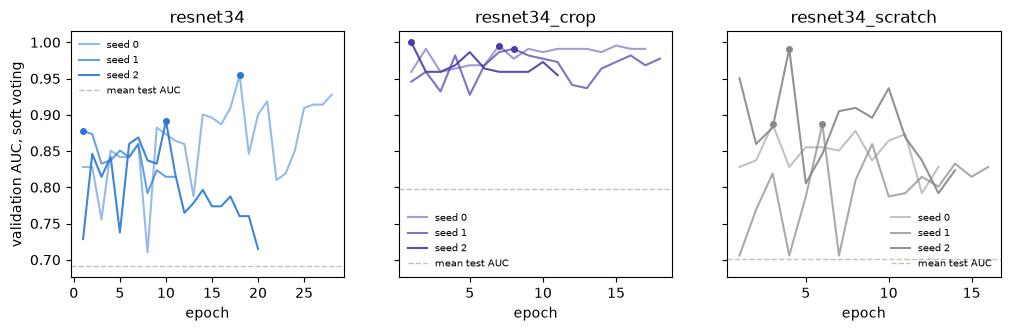

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, mode in zip(ax, MODES):
    for s in range(3):
        h = pd.read_csv(RESULTS / f"yu2024_es_{mode}_seed{s}_history.csv")
        a.plot(h.epoch, h.val_auc, color=COLORS[mode], alpha=0.5 + s * 0.2, label=f"seed {s}" )
        a.plot(h.val_auc.idxmax() + 1, h.val_auc.max(), "o", color=COLORS[mode], ms=4)
    a.axhline(compare.loc[mode, "ES AUC"], color="#c3c2b7", ls="--", lw=1, label="mean test AUC")
    a.set(title=mode, xlabel="epoch"); a.legend(frameon=False, fontsize=7)
ax[0].set_ylabel("validation AUC, soft voting")
plt.show()

### Challenge benchmark

In [11]:
from abus_classification.challenge import benchmark, classification, PUBLISHED
methods = {}
for name, prefix in (("defaults", "yu2024"), ("early stopping", "yu2024_es")):
    for mode in MODES:
        methods[f"{mode}, {name}"] = classification(y, ensemble(prefix, mode))
board = benchmark(methods)
display(board[["ACC", "AUC", "Cls_Score", "Cls_Rank"]].round(4))
PUBLISHED[["ACC", "AUC"]].dropna().sort_values("AUC", ascending=False)

,ACC,AUC,Cls_Score,Cls_Rank
"resnet34, defaults",0.6429,0.7650,0.5403,5/9
"resnet34_crop, defaults",0.6857,0.8250,0.7336,4/9
"resnet34_scratch, defaults",0.6143,0.6867,0.3518,6/9
"resnet34, early stopping",0.6429,0.6758,0.4017,5/9
"resnet34_crop, early stopping",0.7000,0.8250,0.7669,3/9
"resnet34_scratch, early stopping",0.6714,0.7050,0.5137,5/9


,ACC,AUC
T1 SZU,0.7571,0.8892
T3 HU,0.7286,0.7733
T4 KTH,0.7429,0.7708
T10 DGIST,0.7143,0.7642
T2 POSTECH,0.6429,0.6558
T7 PR,0.6000,0.6425
T5 EPITA,0.5429,0.5775
T6 FX,0.5429,0.5675


**What happened.**

- **Early stopping did not improve the result.** Lesion crops with soft voting stay at the same ensemble AUC (0.825). Whole slices fall from 0.765 to 0.676, and no pretraining rises from 0.687 to 0.705. All three paired 95% intervals include zero, so 70 test volumes cannot separate the runs.
- **Five-fold CV points the same way, with less confounding.** Both runs fit the same folds of Train there (one seed). Soft voting falls from 0.709 to 0.645 on whole slices and from 0.846 to 0.815 on crops.
- **Stopping came early, and validation misled it.** Runs stopped between epochs 11 and 28, with the best epoch between 1 and 18. Best validation AUC averages 0.91-0.995 against 0.69-0.80 on Test, on only 30 validation volumes. One crop model was chosen at epoch 1 with validation AUC 1.000.
- **Conclusion.** Near-perfect training accuracy does not explain the gap to the paper, because stopping earlier does not close it. The paper defaults remain our main result: the best is lesion crops with soft voting, ensemble AUC 0.825. We keep them because they follow the paper's schedule and use all the training data. Test was not used to choose any epoch.

**Challenge benchmark.** Classification only: this method uses ground-truth masks and produces no segmentation or detection, so it has no overall rank. Its masks also make the task easier than the teams' task. On the published board, the best run is lesion crops at rank 3 of 9 with early stopping (Cls_Score 0.767) and rank 4 of 9 with defaults (0.734). Both have the same AUC, and the difference comes from accuracy at the 0.5 threshold, 70.0% against 68.6%, which is one test volume.

The paper's ablations are other networks, which we did not run. Our variants are in the first table.

## 6. Protocol

- **Split**: fit on Train + Validation (130 volumes), report on the official Test split (70), split by volume. Second evaluation: the paper's five-fold CV on Train (one seed), whole slices and crops.
- **Positive class**: malignant.
- **Seeds**: 3, with AUC bootstrap CI.
- **Re-run**: `python -m abus_classification.papers.yu2024`, or `python kaggle/push.py yu2024` on the `mralinp` account (private kernel `yu2024-voting`, GPU, about 10 h for all 19 trainings). Finished runs are loaded, not trained again.
- **Early-stopping run**: `kaggle/yu2024-early-stopping/` on T4 x 2, fitting Train only, with Validation choosing the epoch. Output is kept on Drive under `abus-checkpoints/yu2024-early-stopping`, and weights are not stored here.
- **Results**: `results/yu2024/`: slice probabilities, histories and the results table; `yu2024_es_*` for early stopping. `yu2024_test_slices.npz` holds the test slice map, rebuilt from the Test masks.

## 7. Open issues

- **The paper's result does not reproduce.** Our best CV soft voting (crops) falls well short of its 0.986, even on its own protocol. Its internal inconsistencies (Section 3) make the target itself uncertain.
- **Slice count.** We find 3170 tumor slices on Train, the paper 2028. Hypothesis: it filtered small slices or subsampled, which it does not state.
- **Overfitting.** Training reaches about 100% accuracy, with no augmentation by our assumption. Early stopping did not raise test AUC (Section 5). Augmentation and a label-shuffling test have not been run.
- **Validation is much easier than Test here.** Best validation AUC reaches 0.91-0.995, against 0.69-0.80 on Test. Hypothesis: 30 volumes are too few and the split is easier. Not tested.
- **Crops beat whole slices** in our runs, though confidence intervals overlap. The paper does not say which it used.
- **Soft vs hard voting.** Soft voting's AUC gain over hard voting is small here, with no paired test yet (planned for the unified comparison).